# Model 2: Analyzing the Relationship Between AI Exposure and Salaries

## 1. Project Objective

The objective of this model is to investigate the relationship between occupational exposure to Generative AI (GenAI) and salary levels.

This analysis aims to explore whether AI exposure scores provide additional predictive information about salaries when considered alongside other employment-related factors.

The main research question is:

**Does occupational exposure to Generative AI have an association with salary levels, after accounting for other relevant factors?**

## 2. Dataset

This analysis uses the combined dataset created by merging salary information with occupation-level AI exposure scores.

**Dataset:** `ai_jobs_salaries_with_exposure.csv`

The dataset includes information such as:

- Salary in USD
- AI exposure score (`mean_score_2025`)
- Job title and role family
- Work year
- Experience level
- Employment type
- Work mode
- Company size

Only records with valid salary and AI exposure values will be considered in the initial modeling dataset.

## 3. Modeling Approach

Two regression models will be developed and compared:

**Model A — Baseline Salary Model**

Predicts salary using employment-related features without including the AI exposure score.

**Model B — Salary Model with AI Exposure**

Uses the same employment-related features while also including `mean_score_2025`.

Comparing these models will help evaluate whether AI exposure provides additional predictive information beyond the other features.

## 4. Target Variable

The target variable is:

`salary_in_usd`

Since salary distributions can be right-skewed, the analysis will also investigate whether a logarithmic transformation of salary is appropriate.

## 5. Evaluation Metrics

Model performance will be evaluated using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² Score

The two models will be evaluated using consistent data splits and validation procedures.

## 6. Limitations and Interpretation

This is an observational analysis based on available salary and occupational exposure data.

- An association between AI exposure and salary does not establish causation.
- The salary dataset has limited occupational coverage in the merged AI exposure data.
- AI exposure scores represent potential occupational exposure to GenAI, not actual job displacement or salary changes.
- Salary differences may also be influenced by experience, location, industry, company size, and other factors not fully captured in the dataset.

Therefore, the findings will be interpreted as statistical associations and predictive relationships rather than evidence that AI directly increases or decreases salaries.

## 7. Expected Outcome

The final objective is to compare salary prediction performance with and without AI exposure features and assess whether occupational AI exposure contributes useful information to salary modeling.

In [33]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_validate, KFold
import joblib
from pathlib import Path

In [3]:
df = pd.read_csv(
    "../data/ai_jobs_salaries_with_exposure.csv"
)

print("Dataset shape:", df.shape)

Dataset shape: (71913, 22)


In [4]:
model2_df = df.dropna(
    subset=[
        "salary_in_usd",
        "mean_score_2025"
    ]
).copy()

print("Available samples:", model2_df.shape[0])

Available samples: 28521


In [ ]:
print(model2_df["salary_in_usd"].describe())

print("\nMissing values:")
print(model2_df.isnull().sum().sort_values(ascending=False))

print("\nUnique AI Exposure scores:")
print(sorted(model2_df["mean_score_2025"].unique()))

print("\nUnique ISCO groups:")
print(model2_df["ISCO_08"].nunique())


count     28521.000000
mean     143560.567021
std       73476.291833
min       15000.000000
25%       90500.000000
50%      131450.000000
75%      182700.000000
max      800000.000000
Name: salary_in_usd, dtype: float64

Missing values:
work_year                 0
experience_level          0
SD_2025                   0
mean_score_2025           0
Title                     0
ISCO_08                   0
isco_group_hint           0
role_family               0
salary_outlier_flag       0
work_mode                 0
employment_type_label     0
experience_level_label    0
company_size              0
company_location          0
remote_ratio              0
employee_residence        0
salary_in_usd             0
salary_currency           0
salary                    0
job_title                 0
employment_type           0
potential25               0
dtype: int64

Unique AI Exposure scores:
[0.42, 0.44, 0.55, 0.56]

Unique ISCO groups:
4


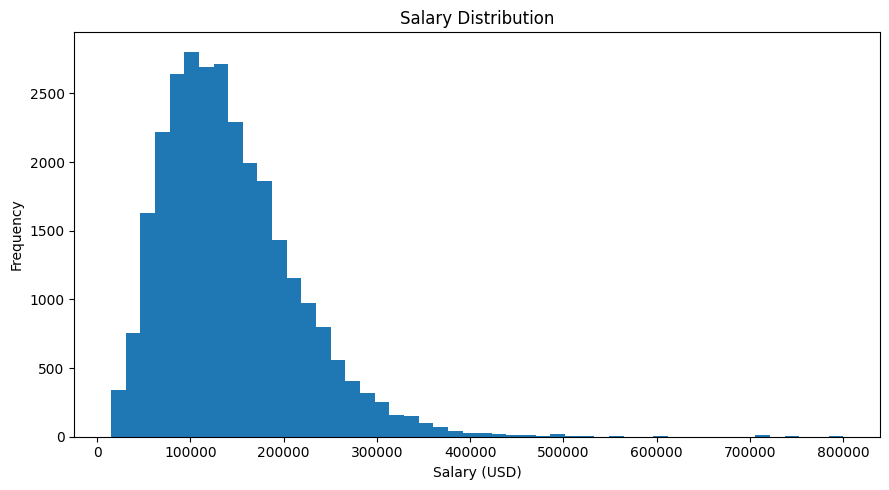

In [ ]:
plt.close()
plt.figure(figsize=(9, 5))

plt.hist(
    model2_df["salary_in_usd"],
    bins=50
)

plt.xlabel("Salary (USD)")
plt.ylabel("Frequency")
plt.title("Salary Distribution")

plt.tight_layout()
plt.show()

In [7]:
print("Mean salary:", model2_df["salary_in_usd"].mean())
print("Median salary:", model2_df["salary_in_usd"].median())

Mean salary: 143560.5670207917
Median salary: 131450.0


In [9]:
group_analysis = (
    model2_df
    .groupby(
        ["ISCO_08", "Title", "mean_score_2025"]
    )["salary_in_usd"]
    .agg(
        count="count",
        mean_salary="mean",
        median_salary="median",
        std_salary="std"
    )
    .reset_index()
    .sort_values("mean_score_2025")
)

group_analysis

,ISCO_08,Title,mean_score_2025,count,mean_salary,median_salary,std_salary
0,1219.0,Business Services and Administration Managers ...,0.42,8335,108601.963527,99450.0,52726.397000
1,1330.0,Information and Communications Technology Serv...,0.44,495,185237.585859,170000.0,86924.111711
3,2519.0,Software and Applications Developers and Analy...,0.55,12475,160638.740040,149600.0,77345.854528
2,2120.0,"Mathematicians, Actuaries and Statisticians",0.56,7216,151556.635116,141843.0,71902.140504


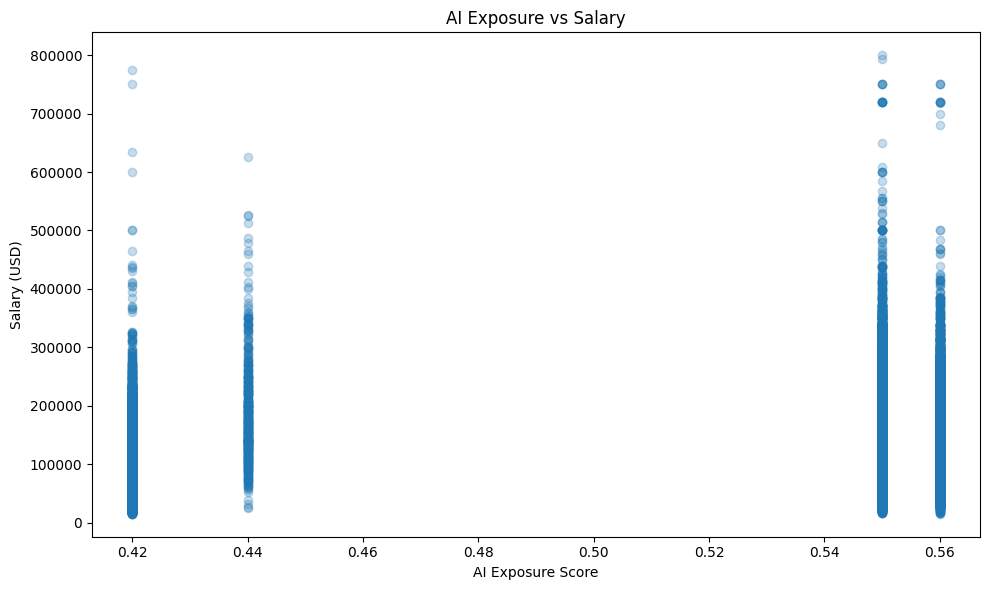

In [ ]:
plt.close()
plt.figure(figsize=(10, 6))

plt.scatter(
    model2_df["mean_score_2025"],
    model2_df["salary_in_usd"],
    alpha=0.25
)

plt.xlabel("AI Exposure Score")
plt.ylabel("Salary (USD)")
plt.title("AI Exposure vs Salary")

plt.tight_layout()
plt.show()

In [13]:
model2_df["log_salary"] = np.log1p(
    model2_df["salary_in_usd"]
)

In [14]:
# Numerical features
numeric_features = ["work_year"]

# Categorical features
categorical_candidates = [
    "experience_level",
    "experience_level_label",
    "employment_type",
    "employment_type_label",
    "work_mode",
    "company_size",
    "role_family"
]

categorical_features = [
    col for col in categorical_candidates
    if col in model2_df.columns
]

# Model A features
features_A = numeric_features + categorical_features

# Model B features
features_B = features_A + ["mean_score_2025"]

print("Numerical:", numeric_features)
print("Categorical:", categorical_features)
print("Model A features:", features_A)
print("Model B features:", features_B)

Numerical: ['work_year']
Categorical: ['experience_level', 'experience_level_label', 'employment_type', 'employment_type_label', 'work_mode', 'company_size', 'role_family']
Model A features: ['work_year', 'experience_level', 'experience_level_label', 'employment_type', 'employment_type_label', 'work_mode', 'company_size', 'role_family']
Model B features: ['work_year', 'experience_level', 'experience_level_label', 'employment_type', 'employment_type_label', 'work_mode', 'company_size', 'role_family', 'mean_score_2025']


In [15]:
X_A = model2_df[features_A]
X_B = model2_df[features_B]

y = model2_df["log_salary"]

X_A_train, X_A_test, y_train, y_test = train_test_split(
    X_A,
    y,
    test_size=0.2,
    random_state=42
)

X_B_train = X_B.loc[X_A_train.index]
X_B_test = X_B.loc[X_A_test.index]

print("Training samples:", len(X_A_train))
print("Testing samples:", len(X_A_test))

Training samples: 22816
Testing samples: 5705


In [16]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [17]:
model_A = Pipeline([
    ("preprocessor", preprocessor),
    ("ridge", Ridge(alpha=1.0))
])

model_B = Pipeline([
    ("preprocessor", preprocessor),
    ("ridge", Ridge(alpha=1.0))
])

# Train Model A
model_A.fit(X_A_train, y_train)

# Train Model B
model_B.fit(X_B_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [18]:
pred_A = np.expm1(model_A.predict(X_A_test))
pred_B = np.expm1(model_B.predict(X_B_test))

actual_salary = np.expm1(y_test)

def evaluate_model(name, y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r2 = r2_score(y_true, y_pred)

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

results = pd.DataFrame([
    evaluate_model("Model A - Without AI Exposure",
                   actual_salary, pred_A),

    evaluate_model("Model B - With AI Exposure",
                   actual_salary, pred_B)
])

results

,Model,MAE,RMSE,R2
0,Model A - Without AI Exposure,47521.047344,65786.491502,0.19992
1,Model B - With AI Exposure,47521.047344,65786.491502,0.19992


In [19]:
model2_df.groupby("role_family")[
    "mean_score_2025"
].nunique().sort_values(ascending=False)

role_family
AI Architect         1
AI Engineer          1
Analytics Manager    1
Computer Vision      1
Data Analyst         1
Data Engineer        1
Data Scientist       1
ML Engineer          1
NLP                  1
Name: mean_score_2025, dtype: int64

In [25]:
categorical_features_new = [
    col for col in categorical_features
    if col != "role_family"
]

features_A_new = numeric_features + categorical_features_new

features_B_new = features_A_new + ["mean_score_2025"]

print("Model A:", features_A_new)
print("Model B:", features_B_new)

Model A: ['work_year', 'experience_level', 'experience_level_label', 'employment_type', 'employment_type_label', 'work_mode', 'company_size']
Model B: ['work_year', 'experience_level', 'experience_level_label', 'employment_type', 'employment_type_label', 'work_mode', 'company_size', 'mean_score_2025']


In [26]:
X_A_new = model2_df[features_A_new]
X_B_new = model2_df[features_B_new]

y = model2_df["log_salary"]

X_A_train, X_A_test, y_train, y_test = train_test_split(
    X_A_new,
    y,
    test_size=0.2,
    random_state=42
)

X_B_train = X_B_new.loc[X_A_train.index]
X_B_test = X_B_new.loc[X_A_test.index]

In [27]:
numeric_features_A = ["work_year"]

numeric_features_B = [
    "work_year",
    "mean_score_2025"
]

In [28]:
preprocessor_A = ColumnTransformer([
    ("num", numeric_transformer, numeric_features_A),
    ("cat", categorical_transformer, categorical_features_new)
])

preprocessor_B = ColumnTransformer([
    ("num", numeric_transformer, numeric_features_B),
    ("cat", categorical_transformer, categorical_features_new)
])

In [29]:
model_A_new = Pipeline([
    ("preprocessor", preprocessor_A),
    ("ridge", Ridge(alpha=1.0))
])

model_B_new = Pipeline([
    ("preprocessor", preprocessor_B),
    ("ridge", Ridge(alpha=1.0))
])

In [30]:
model_A_new.fit(X_A_train, y_train)
model_B_new.fit(X_B_train, y_train)

pred_A_new = np.expm1(
    model_A_new.predict(X_A_test)
)

pred_B_new = np.expm1(
    model_B_new.predict(X_B_test)
)

actual_salary = np.expm1(y_test)

In [31]:
results_new = pd.DataFrame([
    evaluate_model(
        "Model A - Without AI Exposure",
        actual_salary,
        pred_A_new
    ),
    evaluate_model(
        "Model B - With AI Exposure",
        actual_salary,
        pred_B_new
    )
])

results_new

,Model,MAE,RMSE,R2
0,Model A - Without AI Exposure,50181.738571,69582.935603,0.104913
1,Model B - With AI Exposure,48704.589229,67953.052024,0.146354


In [ ]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores_A = cross_validate(
    model_A_new,
    X_A_new,
    y,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

scores_B = cross_validate(
    model_B_new,
    X_B_new,
    y,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

print("Model A CV MAE:", -scores_A["test_score"].mean())
print("Model B CV MAE:", -scores_B["test_score"].mean())

Model A CV MAE: 0.37505656235909957
Model B CV MAE: 0.3634159829743876


## Model 2: Results and Conclusion

### Model Comparison

Two Ridge Regression models were developed to investigate whether occupational AI exposure provides additional predictive information for salary estimation.

- **Model A:** Used employment-related features without AI exposure.
- **Model B:** Used the same features with the addition of `mean_score_2025`.

### Test Set Results

| Metric | Model A | Model B |
|---|---:|---:|
| MAE (USD) | 50,181.74 | 48,704.59 |
| RMSE (USD) | 69,582.94 | 67,953.05 |
| R² | 0.1049 | 0.1464 |

Model B achieved approximately a 2.94% reduction in MAE and a 2.35% reduction in RMSE. Its R² also increased from 0.1049 to 0.1464.

### Cross-Validation Results

Five-fold cross-validation was performed to compare the models across multiple data splits.

| Metric | Model A | Model B |
|---|---:|---:|
| CV MAE (log scale) | 0.3751 | 0.3634 |

Model B achieved a lower average cross-validation MAE, representing an improvement of approximately 3.1%.

### Conclusion

The results suggest that adding occupational AI exposure provides modest additional predictive information for salary estimation within this dataset.

However, the overall predictive performance remains limited, and the findings should be interpreted cautiously.

### Limitations

- The merged dataset contains only four unique ISCO occupation groups and four distinct AI exposure scores.
- AI exposure is constant within each occupation group.
- Random train-test splitting may not fully capture generalization to previously unseen occupations.
- The analysis identifies predictive associations, not causal effects of AI on salaries.

Therefore, these results do not demonstrate that AI exposure directly increases or decreases salaries. Further research using more diverse occupational exposure data and longitudinal salary observations is required.

In [34]:
Path("../models").mkdir(exist_ok=True)
Path("../reports").mkdir(exist_ok=True)

# Save trained models
joblib.dump(model_A_new, "../models/salary_model_without_exposure.joblib")
joblib.dump(model_B_new, "../models/salary_model_with_exposure.joblib")

# Save evaluation results
results_new.to_csv(
    "../reports/salary_model_comparison.csv",
    index=False
)

print("Models and results saved successfully!")

Models and results saved successfully!
